<a href="https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/01_q_learning_tool_agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Train Your RL Agent** · **📍 Ch 1 · Q-learning** → [Ch 2 · REINFORCE](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/02_policy_gradient_reinforce.ipynb) → [Ch 3 · GRPO](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/03_grpo_from_scratch.ipynb) → [Ch 4 · LLM + tools](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/04_llm_tool_use_grpo.ipynb)

# 🧠 Chapter 1 · Teach a tiny AI agent with Reinforcement Learning

### A visual, beginner-friendly Colab adventure ✨

**The mission:** Our little assistant needs to figure out **which tool to use**, **when to stop**, and **how to learn from mistakes**.

✅ Works on a free **CPU** · ✅ No API key · ✅ No installations · ✅ Small code cells

> **Important:** This is **real reinforcement learning**, using a tiny **Q-learning** agent instead of a large language model (LLM). We deliberately start small so you can see every decision. At the end, you'll understand how this connects to *agentic RL for LLMs*, and in Chapters 2–4 you'll build that connection yourself, ending with a real LLM that learns to use tools.

## 1 · What is Reinforcement Learning (RL)? 🎮

Imagine teaching a puppy a trick. You don't give it a huge list of rules. You let it try, tell it how it did, and repeat.

- **Agent:** the learner (our assistant).
- **Action:** something it chooses (like picking a tool).
- **Reward:** feedback (+1 for success, negative for a mistake).
- **Learning:** it remembers which actions tend to work.

**RL = try → see what happens → get feedback → improve.**

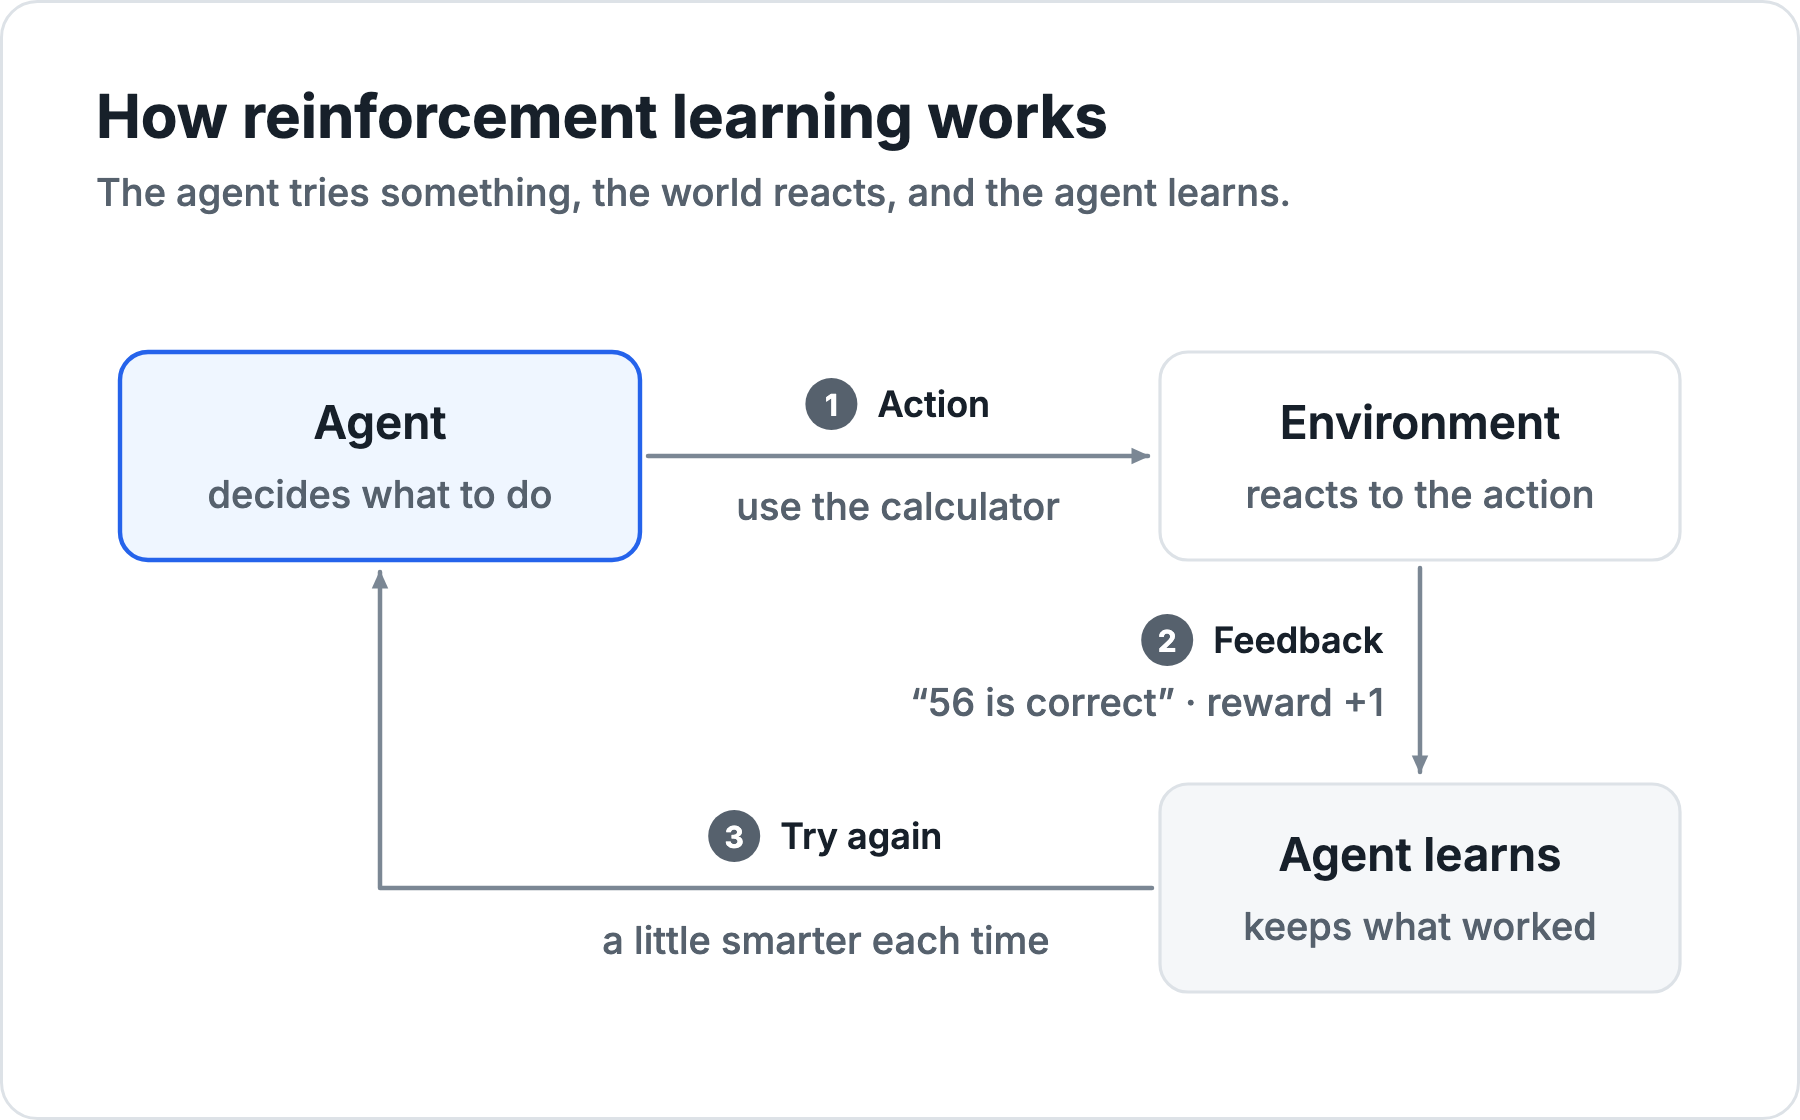

💡 **One-minute check:** If the agent chooses a bad tool, does somebody rewrite its instructions by hand? **No!** It gets a small penalty and changes its own action scores during training.

## 2 · What makes RL *agentic*? 🤖

A simple RL learner might pick **one action** and get a score. An **agentic** learner can make a *sequence* of choices:

1. Read a question.
2. Decide which tool to call.
3. Look at the tool's result.
4. Decide whether to **finish** or **try another tool**.

The same idea appears in tool-using AI assistants: **observe → act → observe → act** until the task is done.

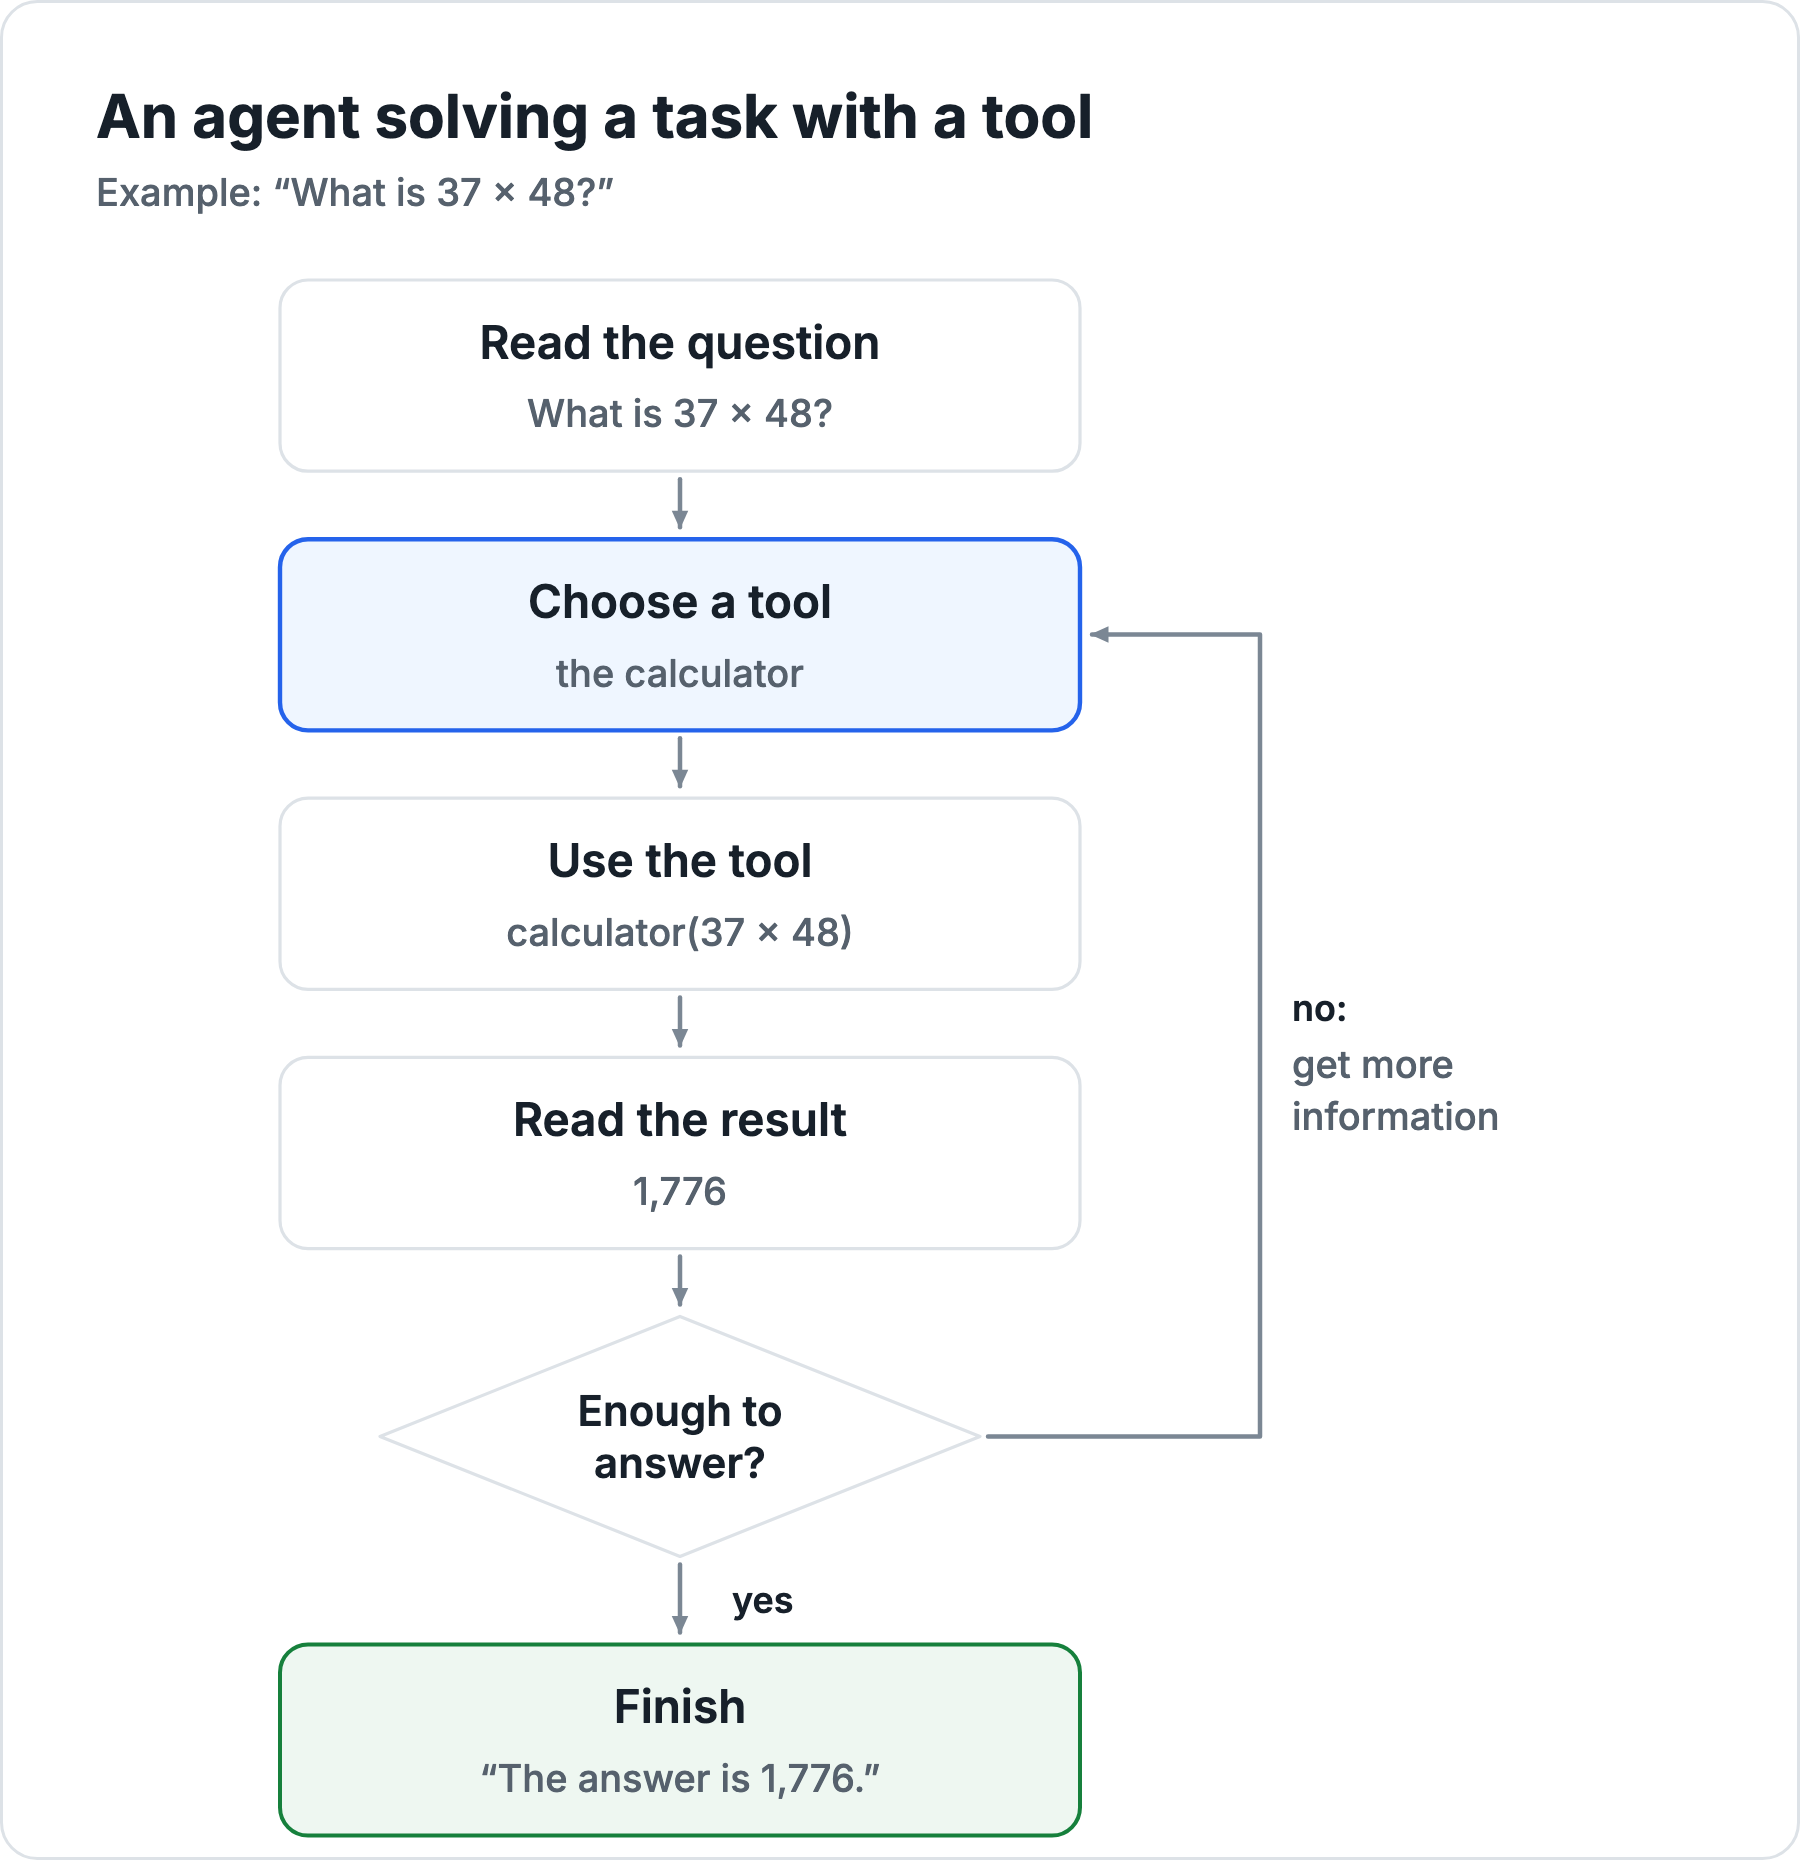

When the task is over, the agent learns from **the whole task at once**:

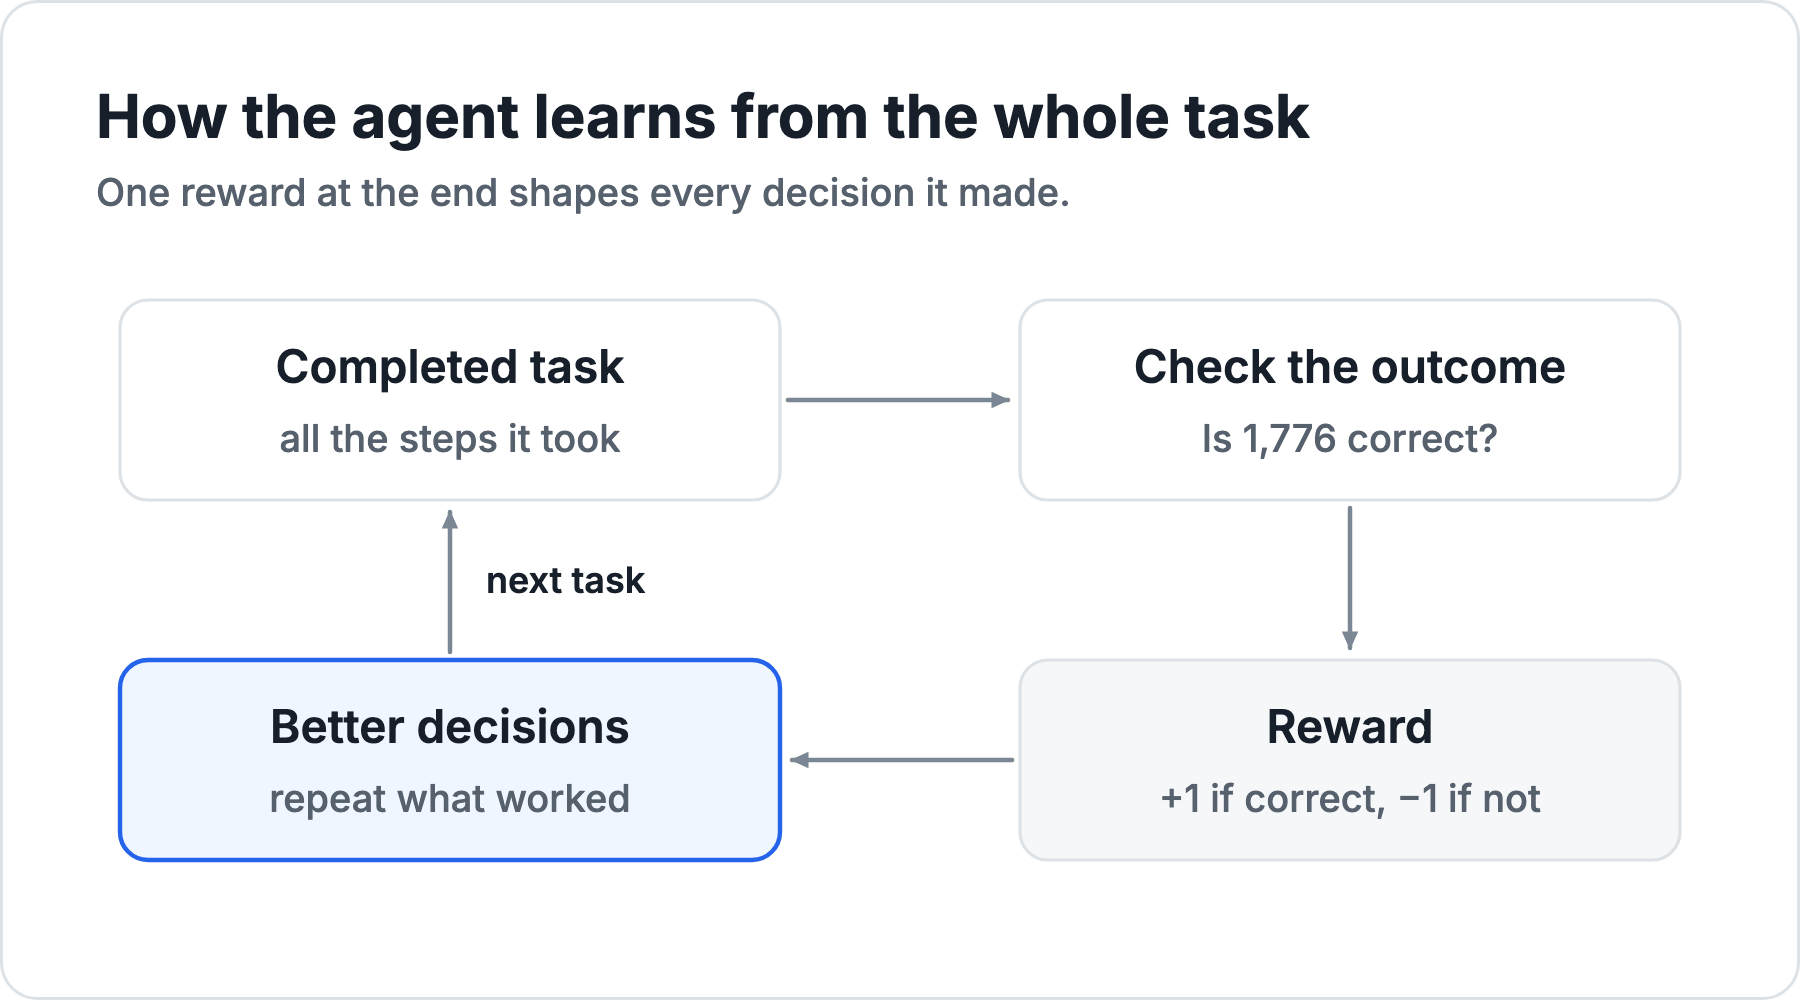

**Our tiny version is a real sequential decision problem.** The assistant learns using **Q-learning**, a classic RL method. LLM-based agents learn tool use with algorithms such as **GRPO**. You'll implement GRPO from scratch in Chapter 3 and use it to train a real LLM in Chapter 4.

## 3 · Meet our agent and its four buttons 🎛️

The assistant can choose **Calculator**, **Dictionary**, **Reply**, or **Finish**.

| Someone asks… | Helpful first button |
|:--|:--|
| “What is 7 × 8?” | Calculator |
| “What does orbit mean?” | Dictionary |
| “Say hello!” | Reply |

After it gets an answer, the right next button is **Finish**.

Let's give our assistant these buttons. 👇

In [1]:
import random
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 14, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
ACCENT, GREY = "#2563EB", "#9AA4AE"   # course colors

random.seed(12)
buttons = ["Calculator", "Dictionary", "Reply", "Finish"]
topics = ["math", "words", "chat"]
print("Our agent can press:", buttons)

Our agent can press: ['Calculator', 'Dictionary', 'Reply', 'Finish']


### Tiny tools, not pretend answers

We give each button a little job. The calculator actually multiplies numbers; the dictionary and reply tool look up short answers.

In [2]:
meanings = {
    "orbit": "a path around another object",
    "habitat": "an animal's natural home",
    "gravity": "a force pulling things together",
}
greetings = {"hello": "Hello!", "thanks": "You're welcome!"}

In [3]:
def use_tool(button, task):
    kind, question, data = task
    if button == "Calculator" and kind == "math":
        return str(data[0] * data[1])
    if button == "Dictionary" and kind == "words":
        return meanings[data]
    if button == "Reply" and kind == "chat":
        return greetings[data]
    return None  # Wrong tool: no answer

### Try a button yourself! 🔍

Change `"Calculator"` to `"Dictionary"` and rerun. What happens?

In [4]:
example = ("math", "What is 7 x 8?", (7, 8))
print("Tool result:", use_tool("Calculator", example))

Tool result: 56


## 4 · Give our agent practice questions 📚

We use just a few friendly examples—no downloads and no private data. Each question has a **topic**, which our tiny agent can already see. It learns *what to do with that topic*, not how to read English.

In [5]:
practice = [
    ("math", "What is 3 x 4?", (3, 4)),
    ("math", "What is 6 x 8?", (6, 8)),
    ("words", "Define orbit", "orbit"),
    ("words", "Define habitat", "habitat"),
    ("chat", "Say hello", "hello"),
    ("chat", "Say thanks", "thanks"),
]

We also make **new questions** for our final test. The agent will not practise on these exact tasks.

In [6]:
test_tasks = [
    ("math", "What is 9 x 11?", (9, 11)),
    ("words", "Define gravity", "gravity"),
    ("chat", "Say hello to my friend", "hello"),
]
print("Practice questions:", len(practice))
print("New test questions:", len(test_tasks))

Practice questions: 6
New test questions: 3


## 5 · Why two decisions matter 🌱

Our assistant has only **two situations** (also called *states*):

- **Needs information** (`"needs_tool"` in the code): it still has no answer.
- **Has the information** (`"has_answer"` in the code): a useful tool returned something, but the assistant hasn't finished yet.

A good agent learns that finishing **too early** is a mistake—and that using **Finish** after getting an answer is a success.

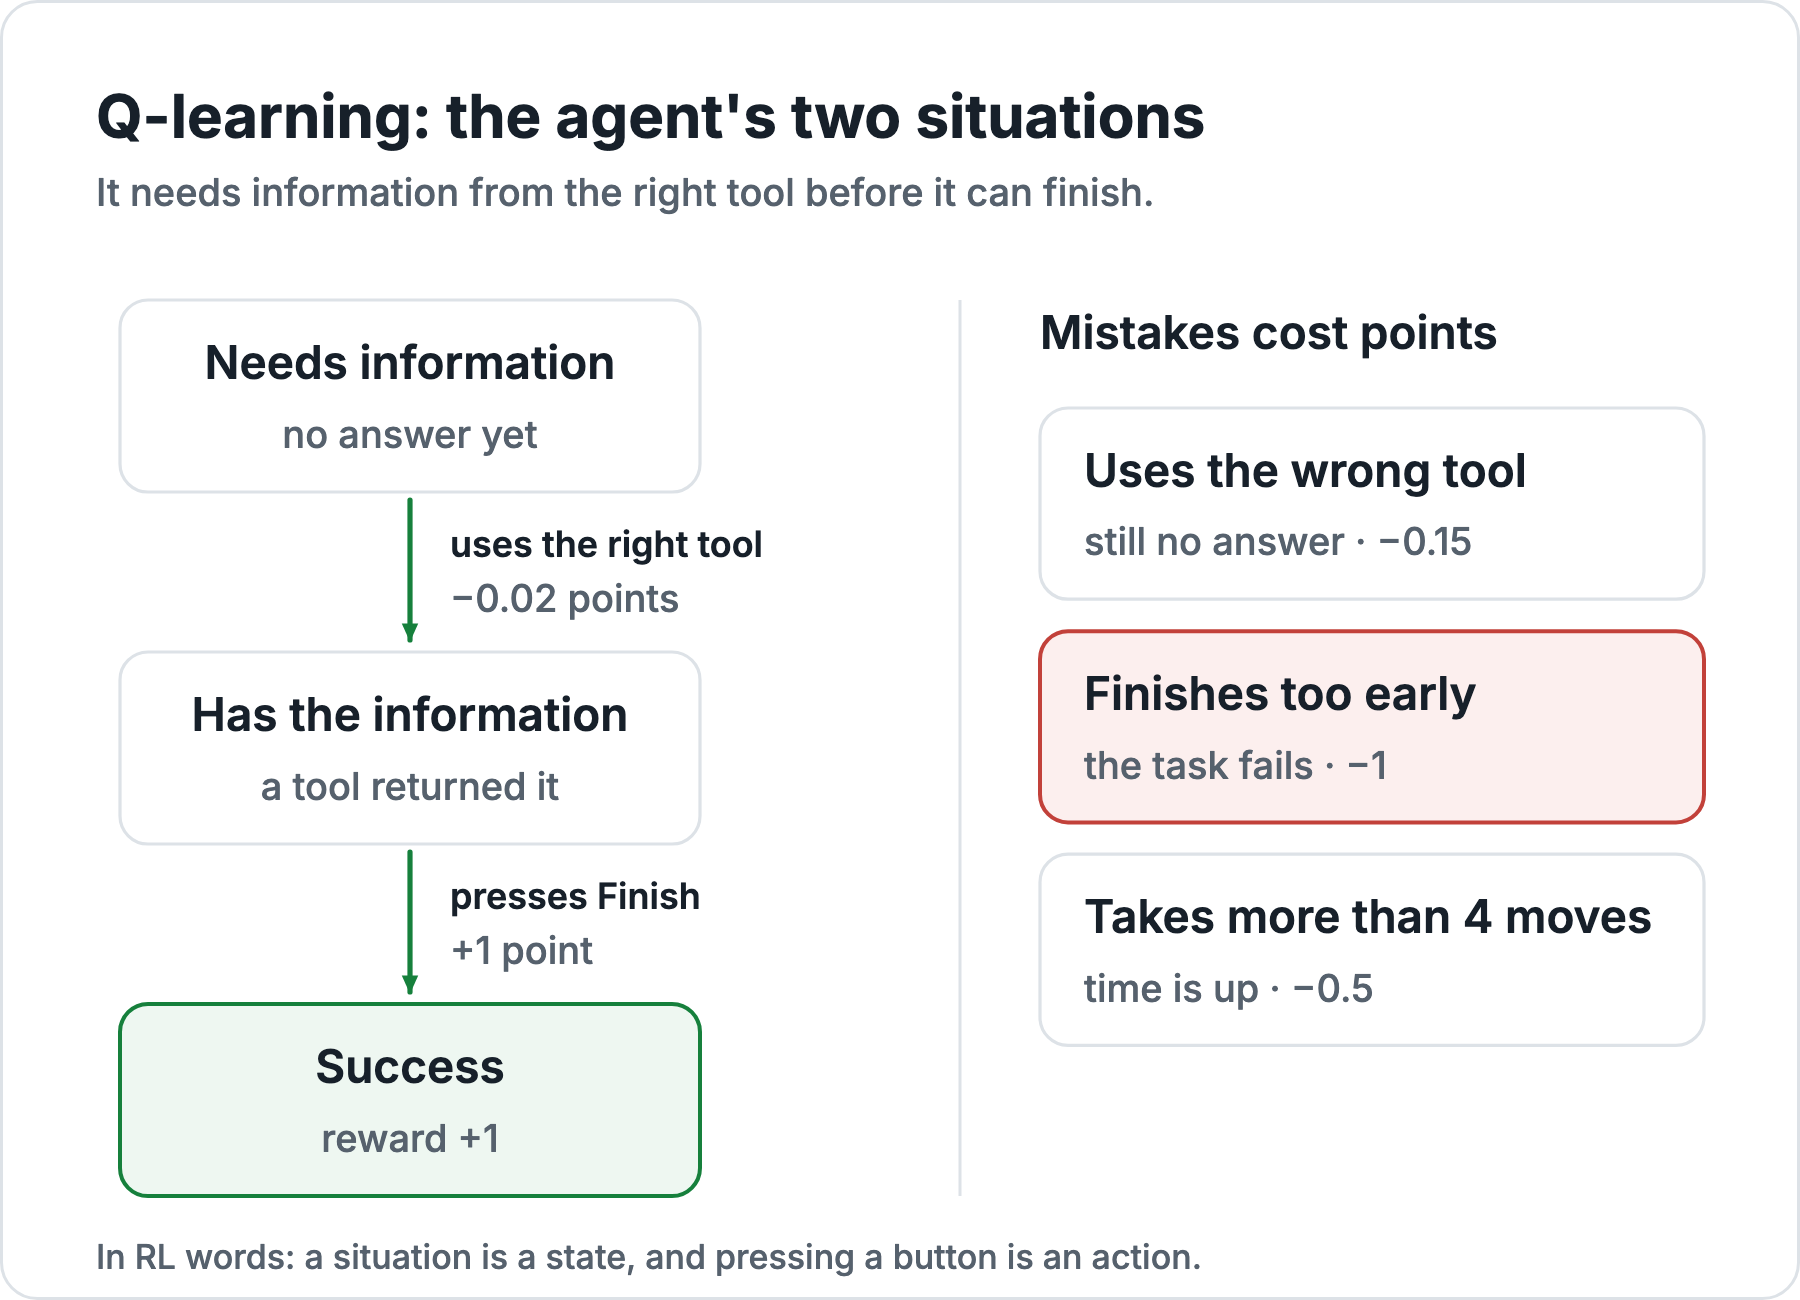

### The reward rules 🏆

| What happens? | Points |
|:--|--:|
| Finish **with** an answer | **+1** |
| Finish **without** an answer | **−1** |
| Wrong tool | −0.15 |
| Useful tool | −0.02 (tiny cost) |

Why is a useful tool not immediately worth +1? Because we want the agent to **complete the task**, not endlessly click tools. The reward arrives **after** the final decision. That's the key challenge in sequential RL!

## 6 · Build our tiny world 🌍

The world tells the agent what happens after it presses a button. `Finish` ends the episode. A successful tool moves us to `"has_answer"`.

In [7]:
def step(task, state, button, answer):
    topic, stage = state
    if button == "Finish":
        return state, (1 if answer else -1), True, answer
    result = use_tool(button, task)
    if result is not None:
        return (topic, "has_answer"), -0.02, False, result
    return state, -0.15, False, answer

Let's test the rules without any learning yet.

In [8]:
start = ("math", "needs_tool")
next_state, points, done, answer = step(example, start, "Calculator", None)
print("New situation:", next_state)
print("Tool answer:", answer)
print("Reward so far:", points)

New situation: ('math', 'has_answer')
Tool answer: 56
Reward so far: -0.02


In [9]:
_, points, done, _ = step(example, next_state, "Finish", answer)
print("Pressed Finish → reward:", points)
print("Task complete?", done)

Pressed Finish → reward: 1
Task complete? True


## 7 · Give the agent a very small brain 🧠

Instead of a giant neural network, we'll use a **scoreboard** (called a **Q-table**).

For each situation and button, the agent keeps a number. **Higher number = more promising action.**

At first, every number is **0**. The agent has no idea what to choose!

In [10]:
Q = {
    (topic, stage): {button: 0.0 for button in buttons}
    for topic in topics
    for stage in ("needs_tool", "has_answer")
}
print("Math, before training:", Q[("math", "needs_tool")])

Math, before training: {'Calculator': 0.0, 'Dictionary': 0.0, 'Reply': 0.0, 'Finish': 0.0}


### How does it pick a button?

Mostly it chooses the button with the highest score. Sometimes during training it **explores** by trying something random.

That's how an RL agent balances what it already knows and what it might discover.

In [11]:
def choose_button(state, explore=0):
    if random.random() < explore:
        return random.choice(buttons)
    scores = Q[state]
    best = max(scores.values())
    options = [b for b in buttons if scores[b] == best]
    return random.choice(options)

## 8 · The learning rule (no math degree needed!) 🔁

> **The agent updates its score for an action using what happened now and what might happen next.**

The agent asks three questions after every move:

1. **What did I think this button was worth?**
2. **What points did I just get?**
3. **Could my *next* move help me get more points?**

Then it nudges its score toward the new estimate. This is the essence of **Q-learning**.

**No need to memorize the equation:** `new score = old score + small correction`.

### A worked example

The agent has an answer and presses **Finish**. Its old score for that move is **0**. It gets **+1**, and the task is over, so there is no future to add.

- better guess = reward now + 0.9 × best future score = 1 + 0.9 × 0 = **1**
- correction = better guess − old score = 1 − 0 = **1**
- new score = old score + 0.25 × correction = 0 + 0.25 × 1 = **0.25**

The score moved a quarter of the way toward what actually happened. Repeat this many times and it settles close to the true value of that move.

#### Going deeper (optional): the Q-learning formula

$$Q(s, a) \leftarrow Q(s, a) + \alpha \big( r + \gamma \max_{a'} Q(s', a') - Q(s, a) \big)$$

| Symbol | In plain words | In our code |
|:--|:--|:--|
| $Q(s, a)$ | the score for pressing button $a$ in situation $s$ | `Q[state][button]` |
| $r$ | the reward just received | `points` |
| $\max_{a'} Q(s', a')$ | the best score available in the next situation | `max(Q[next_state].values())` |
| $\gamma$ | how much future points count | `0.9` |
| $\alpha$ | how big a step to take | `0.25` |

In [12]:
def learn(state, button, points, next_state, finished):
    future = 0 if finished else max(Q[next_state].values())
    better_guess = points + 0.9 * future
    old_guess = Q[state][button]
    Q[state][button] += 0.25 * (better_guess - old_guess)

**A quick translation:** `0.9` means future rewards matter; `0.25` means change the score a little rather than all at once. This is a **genuine RL update**, not a hard-coded answer table.

## 9 · One full adventure (an episode) 🚶

An **episode** starts with a question and ends when the agent presses Finish—or after four moves. The four-move limit prevents it from getting stuck forever.

We'll keep each piece of the code short.

In [13]:
def take_turn(task, state, answer, training, last_turn):
    button = choose_button(state, 0.25 if training else 0)
    new_state, points, done, answer = step(task, state, button, answer)
    if last_turn and not done:
        points -= 0.5  # Running out of moves is bad
    if training:
        learn(state, button, points, new_state, done or last_turn)
    return new_state, answer, done, (button, points, answer)

In [14]:
def run_episode(task, training=False):
    state, answer, trail = (task[0], "needs_tool"), None, []
    for move in range(4):
        state, answer, done, row = take_turn(
            task, state, answer, training, move == 3)
        trail.append(row)
        if done:
            break
    return bool(done and answer), trail

### Watch a first attempt 🍿

A new agent may get lucky, click the wrong tool, or finish too soon. Nothing has been trained yet.

In [15]:
success, trail = run_episode(example)
for button, points, answer in trail:
    print(f"Pressed {button:10} | reward {points:+.2f} | answer: {answer}")
print("Success:", success)

Pressed Reply      | reward -0.15 | answer: None
Pressed Calculator | reward -0.02 | answer: 56
Pressed Finish     | reward +1.00 | answer: 56
Success: True


**What just happened?** Every score is still 0, so the agent picks buttons at random. Sometimes it gets lucky and sometimes it doesn't. Run the cell again to watch a different attempt.

## 10 · Before learning: how good is it? 📏

For a fair comparison, we'll test the **same three unseen questions** before and after learning. We repeat each one to smooth out random guesses. These trials do **not** update the brain.

In [16]:
def test_accuracy(questions, repeats=100):
    outcomes = [run_episode(task)[0]
                for task in questions for _ in range(repeats)]
    return sum(outcomes) / len(outcomes)

In [17]:
before = test_accuracy(test_tasks)
print(f"Before training: {before:.0%} of tasks completed")

Before training: 20% of tasks completed


**What just happened?** Pressing buttons at random, the agent completes only about **1 task in 5**, by luck.

## 11 · Time to train! 🎯

Each round, the agent tries one practice question. The reward tells it what to remember.

👇 **Experiment:** Try changing `TRAIN_ROUNDS` from `600` to `30`, then run the notebook again. Does it still learn?

In [18]:
TRAIN_ROUNDS = 600  # 👈 Try 30, 200, 600, or 1000
history = []
for round_number in range(TRAIN_ROUNDS):
    task = random.choice(practice)
    success, _ = run_episode(task, training=True)
    history.append(int(success))
print("Practice complete! 🎉")

Practice complete! 🎉


### Look at the learning curve 📈

Each point is the percentage of successful practice rounds among the **most recent 30 tries**. The curve may be bumpy: that's normal because training includes exploration.

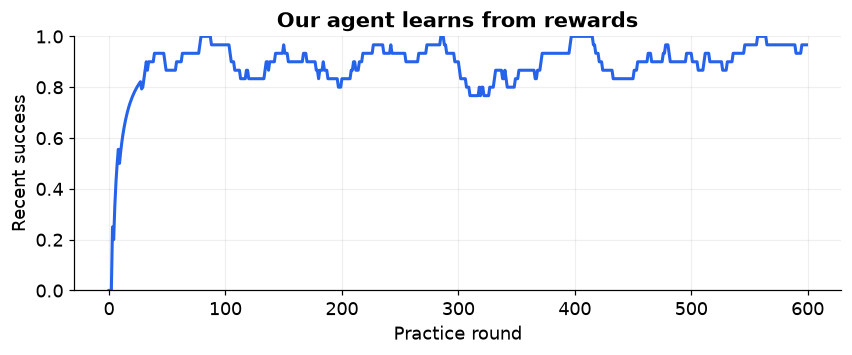

In [19]:
recent = [sum(history[max(0, i-29):i+1]) / min(30, i+1)
          for i in range(len(history))]
plt.figure(figsize=(9, 3))
plt.plot(recent, color=ACCENT, linewidth=2)
plt.ylim(0, 1)
plt.xlabel("Practice round")
plt.ylabel("Recent success")
plt.title("Our agent learns from rewards")
plt.grid(alpha=0.2)
plt.show()

**What just happened?** Early rounds often fail because the agent is still guessing. Within about 100 rounds, nearly every round succeeds. The small dips are the random exploring moves (25% of the time).

## 12 · See what the brain learned 🔎

Let's reveal the highest-scoring action for each question type and for each situation.

In [20]:
for topic in topics:
    first = choose_button((topic, "needs_tool"))
    second = choose_button((topic, "has_answer"))
    print(f"{topic:5} → {first:10} → {second}")

math  → Calculator → Finish
words → Dictionary → Finish
chat  → Reply      → Finish


Notice the **two decisions**: first the appropriate tool, then **Finish**. That two-step planning is why this is more than a one-click reward toy.

## 13 · The big reveal: before vs. after 🏆

We're now testing the **same held-out tasks** again, without exploration or learning.

In [21]:
after = test_accuracy(test_tasks)
print(f"Before: {before:.0%} completed")
print(f"After:  {after:.0%} completed")
print(f"Change: {after - before:+.0%}")

Before: 20% completed
After:  100% completed
Change: +80%


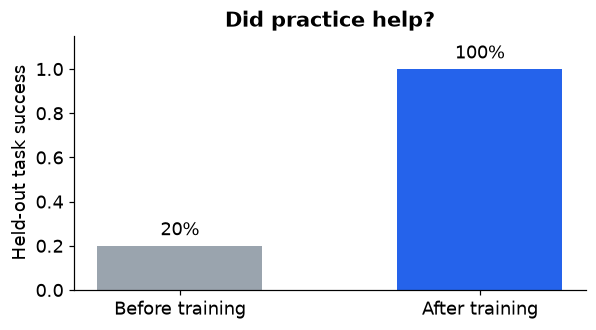

In [22]:
plt.figure(figsize=(6, 3))
bars = plt.bar(["Before training", "After training"], [before, after], color=[GREY, ACCENT], width=0.55)
plt.bar_label(bars, labels=[f"{before:.0%}", f"{after:.0%}"], padding=4, fontsize=12)
plt.ylim(0, 1.15)
plt.ylabel("Held-out task success")
plt.title("Did practice help?")
plt.show()

**What does this result prove?** In this *small simulated world*, a Q-learning agent can learn a short sequence of tool actions. It **does not** prove that an LLM became smarter, and it does not measure real-world agent reliability.

## 14 · Ask your trained agent a new question! 💬

Change the two numbers below, then run the cell. Watch the sequence of decisions.

In [23]:
my_question = ("math", "What is 12 x 13?", (12, 13))  # 👈 edit me
success, trail = run_episode(my_question)
for button, points, answer in trail:
    print("Agent chose:", button, "→", answer)
print("Finished correctly?", success)

Agent chose: Calculator → 156
Agent chose: Finish → 156
Finished correctly? True


**What just happened?** The trained agent read its scoreboard: **Calculator** has the highest score when it needs information about math, and **Finish** has the highest score once it has the answer.

## 15 · Your turn: small experiments 🧪

1. **Less practice:** Change `TRAIN_ROUNDS = 600` to `30`. Does it reliably learn?
2. **Explore more:** In `take_turn`, replace `0.25` with `0.60`. What changes?
3. **Change the mission:** Add a new math problem to `practice` and another to `test_tasks`.
4. **Change a reward and see what happens:** in `step`, change the reward for finishing without an answer from `-1` to `0`. Does the agent still bother to use a tool first?

After changing an earlier cell, use **Runtime → Restart and run all** to get a clean experiment.

**Think about it:** Why would pressing Finish immediately be a bad idea? When might exploring help?

## 16 · How this connects to LLM Agentic RL 🚀

Our tiny Q-table and a modern LLM use the **same general learning story**:

| In this beginner notebook | In LLM agentic RL |
|:--|:--|
| Tiny Q-table (six situations) | Neural network with many parameters |
| Four fixed buttons | Many possible tool calls or text actions |
| Simulated calculator/dictionary | Real tool APIs or simulated environments |
| Q-learning score update | Methods such as policy optimization / GRPO |
| Exact success reward | Verifiable task outcome and/or richer rewards |

**What doesn't transfer automatically?** Understanding arbitrary English, choosing tool arguments, dealing with long conversations, and safely using real tools. Those are much harder challenges.

### Want the next level? Keep climbing the ladder 🪜

- **[Chapter 2 · REINFORCE](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/02_policy_gradient_reinforce.ipynb)**: replace the scoreboard with *probabilities*, the way LLMs think. (CPU)
- **[Chapter 3 · GRPO from scratch](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/03_grpo_from_scratch.ipynb)**: the algorithm behind DeepSeek-R1, on an agent that reads the question. (CPU)
- **[Chapter 4 · LLM + tools](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/04_llm_tool_use_grpo.ipynb)**: teach Qwen2.5-0.5B to use tools with GRPO. (free Colab GPU)

## 🎓 Congratulations — you trained an agent!

You learned:

- ✅ **Reinforcement learning:** learn from rewards, not explicit instructions for each decision.
- ✅ **Agentic RL:** make *multiple* decisions, use a tool, observe, and decide what to do next.
- ✅ **Q-learning:** learn action scores using both immediate rewards and possible future rewards.
- ✅ **Exploration:** sometimes trying something new helps learning.
- ✅ **Evaluation:** test on questions that weren't used for practice.

**Your one-sentence takeaway:** *An agent learns by trying actions in a world, observing the results, and updating which actions it chooses next.*

### ➡️ Next: [Ch 2 · REINFORCE](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/02_policy_gradient_reinforce.ipynb)

<a href="https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/02_policy_gradient_reinforce.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

⭐ Found this useful? [Star Train Your RL Agent on GitHub](https://github.com/HamedKhosravi99/Train-Your-RL-Agent) so other beginners can find it.